In [1]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import time
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False 

In [2]:
API_KEY = "8c4ee3c7c3bf7985a786b7a491304991"
BASE_URL = 'https://restapi.amap.com/v5/place/text'

In [3]:
def fetch_api_pois(keywords, region="500154", page_size=25, page_num=1, key=API_KEY):
    params = {
        "key": key,
        "keywords": keywords,
        "region": region,
        "city_limit": "true",
        "output": "JSON",
        "page_size": page_size,
        "page": page_num
    }
    response = requests.get(BASE_URL, params=params)
  
    if response.status_code == 200:
        data = response.json()
        if data.get("status") != "1":
            print(f"Error fetching POIs: {data.get('info')}")
            return pd.DataFrame()
    else:
        print(f"HTTP Error: {response.status_code}")
        return []
    pois = data.get('pois', [])
    records = []
    for p in pois:
        loc = p.get('location', '')
        if loc and ',' in loc:
            lon, lat = map(float, loc.split(','))
            records.append({
                'name': p.get('name'),
                'type': p.get('type'),
                'category': keywords,      
                'address': p.get('address'),
                'district': p.get('adname'), 
                'lon': lon,
                'lat': lat
            })
    return pd.DataFrame(records)
    

In [4]:
target_types = ['医院', '学校', '咖啡厅', '公交站']
poi_dfs = []

for p_type in target_types:
    print(f"正在获取【{p_type}】数据...")
    df_temp = fetch_api_pois(keywords=p_type, region="500154", page_size=25, page_num=1)
    if not df_temp.empty:
        poi_dfs.append(df_temp)
    time.sleep(0.3) 

# 合并所有数据
all_pois_df = pd.concat(poi_dfs, ignore_index=True)
print(f"✓ 数据获取完毕，共获取到 {len(all_pois_df)} 条 POI 数据。")
display(all_pois_df.head(5))

正在获取【医院】数据...
正在获取【学校】数据...
正在获取【咖啡厅】数据...
正在获取【公交站】数据...
✓ 数据获取完毕，共获取到 100 条 POI 数据。


,name,type,category,address,district,lon,lat
0,开州区人民医院,医疗保健服务;综合医院;三级甲等医院,医院,安康街8号,开州区,108.404923,31.165553
1,开州区中医院,医疗保健服务;综合医院;综合医院,医院,开州大道西206号,开州区,108.381932,31.160621
2,开州博爱医院,医疗保健服务;综合医院;综合医院,医院,兴合社区学林街48号,开州区,108.367393,31.152242
3,重庆开州康桥医院,医疗保健服务;综合医院;综合医院,医院,开州大道花样年华小区,开州区,108.411950,31.171538
4,开州区郭家镇卫生院,医疗保健服务;综合医院;卫生院,医院,S102(东里街),开州区,108.480244,31.285329


In [5]:
# 创建几何点 Point
geometry = [Point(xy) for xy in zip(all_pois_df['lon'], all_pois_df['lat'])]

# 构建 GeoDataFrame，初始坐标系为地理坐标系 WGS84 / GCJ-02 
gdf_gcs = gpd.GeoDataFrame(all_pois_df, geometry=geometry, crs="EPSG:4326")
print(f"原始地理坐标系: {gdf_gcs.crs}")

# 投影转换：转为最契合重庆经度的 UTM Zone 49N: 'EPSG:32649'
gdf_proj = gdf_gcs.to_crs(epsg=32649)
print(f"转换后投影坐标系: {gdf_proj.crs}")

# 查看投影后的平面坐标（X, Y 以米为单位）
print("投影后的几何坐标示例 :")
print(gdf_proj[['name', 'category', 'geometry']].head())

原始地理坐标系: EPSG:4326
转换后投影坐标系: EPSG:32649
投影后的几何坐标示例 :
        name category                        geometry
0    开州区人民医院       医院   POINT (252647.69 3450849.743)
1     开州区中医院       医院   POINT (250442.63 3450354.519)
2     开州博爱医院       医院  POINT (249034.198 3449458.326)
3   重庆开州康桥医院       医院  POINT (253333.214 3451497.672)
4  开州区郭家镇卫生院       医院   POINT (260132.159 3463964.38)


In [6]:
import folium

# 确定视野中心（自适应数据平均经纬度）
center_lat = all_pois_df['lat'].mean()
center_lon = all_pois_df['lon'].mean()

# 创建底图
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='OpenStreetMap'
)

# 颜色映射字典
colors = {
    '医院': 'red',
    '学校': 'blue',
    '咖啡厅': 'purple',
    '公交站': 'green'
}

# 单层遍历所有数据并添加标记
for idx, row in all_pois_df.iterrows():
    cat = row.get('category', '其他')
    c = colors.get(cat, 'gray')
    
    # 构造富文本 HTML 弹窗内容（展示：名称、类别、行政区、详细地址）
    popup_txt = (
        f"<b>{row.get('name', '未知名称')}</b><br>"
        f"类别: {cat}<br>"
        f"行政区: {row.get('district', '重庆市开州区')}<br>"
        f"地址: {row.get('address', '无详细地址')}"
    )
    
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=5,
        color=c,                     # 圆圈外边框颜色
        fill=True,
        fill_color=c,                # 填充颜色
        fill_opacity=0.7,            # 填充透明度
        tooltip=f"[{cat}] {row.get('name', '')}",     # 鼠标悬浮提示
        popup=folium.Popup(popup_txt, max_width=250)  # 点击弹出富文本信息框
    ).add_to(m)

# 保留悬浮图例，提升地图可读性
legend_html = '''
<div style="position: fixed; top: 10px; right: 10px; width: 140px; 
            background: white; border: 2px solid grey; z-index: 9999; 
            font-size: 13px; padding: 10px; border-radius: 4px;">
<p style="margin: 0 0 5px 0;"><strong>POI类型</strong></p>
<p style="margin: 2px 0;"><i class="fa fa-circle" style="color:red"></i> 医院</p>
<p style="margin: 2px 0;"><i class="fa fa-circle" style="color:blue"></i> 学校</p>
<p style="margin: 2px 0;"><i class="fa fa-circle" style="color:purple"></i> 咖啡厅</p>
<p style="margin: 2px 0;"><i class="fa fa-circle" style="color:green"></i> 地铁站</p>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))
# 导出为交互式 HTML 网页
html_path = "./data/poi_interactive_map.html"
m.save(html_path)
m

findfont: Failed to find font weight bold, now using 400.
findfont: Failed to find font weight bold, now using 400.


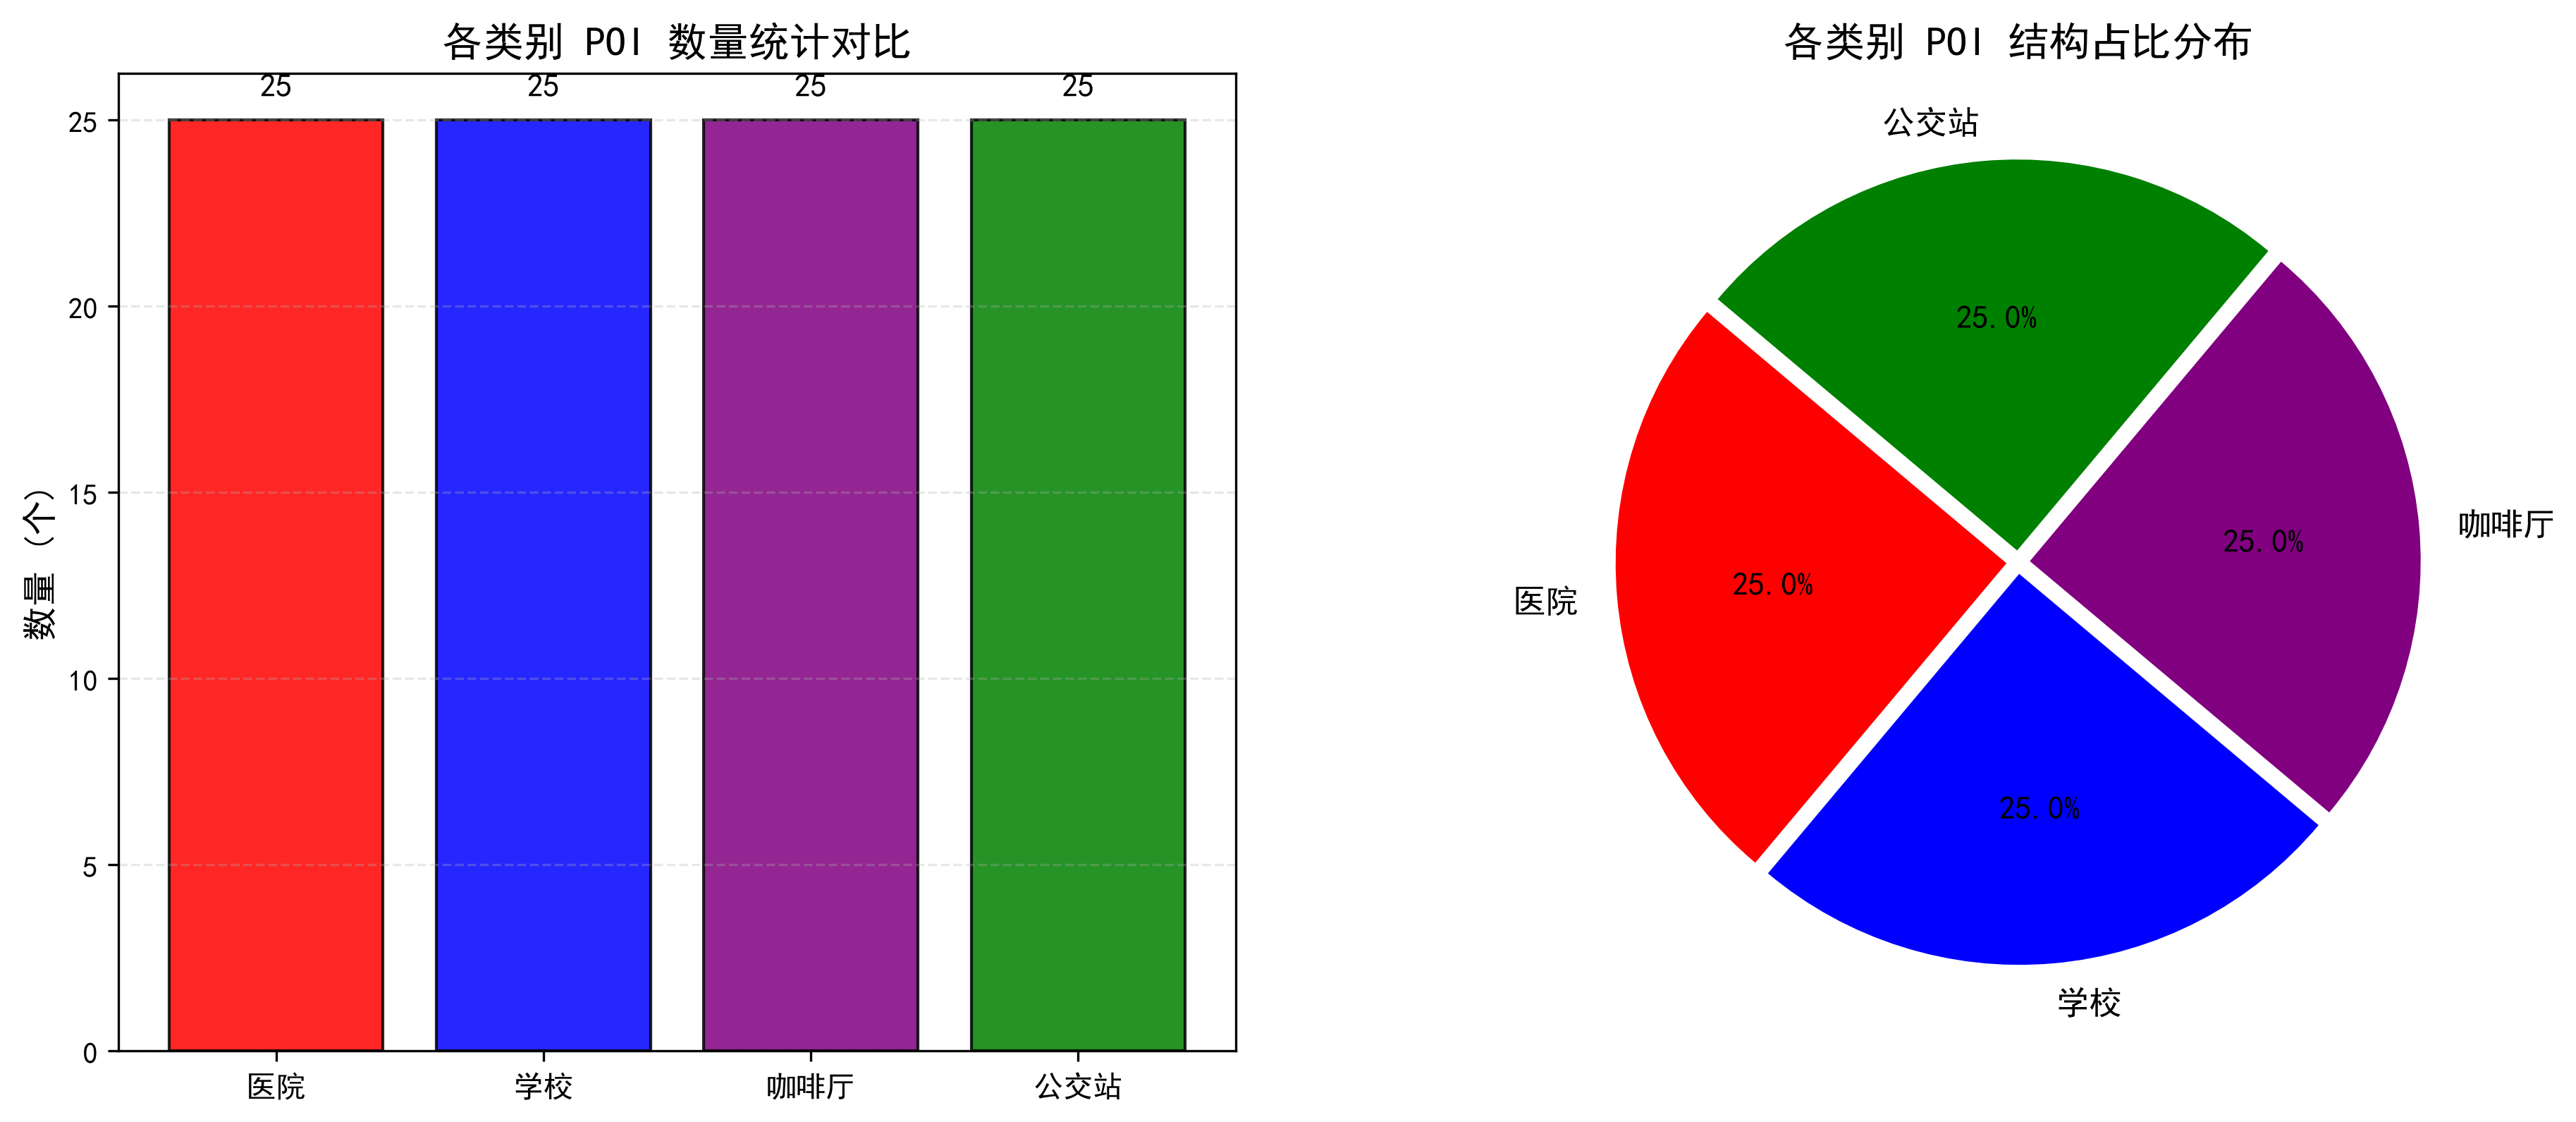

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
type_counts = gdf_proj['category'].value_counts()
colors = [colors.get(k, 'gray') for k in type_counts.index]

bars = ax1.bar(type_counts.index, type_counts.values, color=colors, edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{int(height)}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax1.set_title("各类别 POI 数量统计对比", fontsize=14, fontweight='bold')
ax1.set_ylabel("数量 (个)", fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

ax2.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=140,
    explode=[0.03] * len(type_counts), 
    textprops={"fontsize": 11},
)
ax2.set_title("各类别 POI 结构占比分布", fontsize=14, fontweight="bold")

# 保存数据为 GeoPackage 和 CSV
gdf_proj.to_file("./data/datapoi_projected.gpkg", driver="GPKG")
all_pois_df.to_csv("./data/poi_raw_data.csv", index=False, encoding="utf-8-sig")

【高级分析】正在生成 POI 空间密度 2D 直方图...


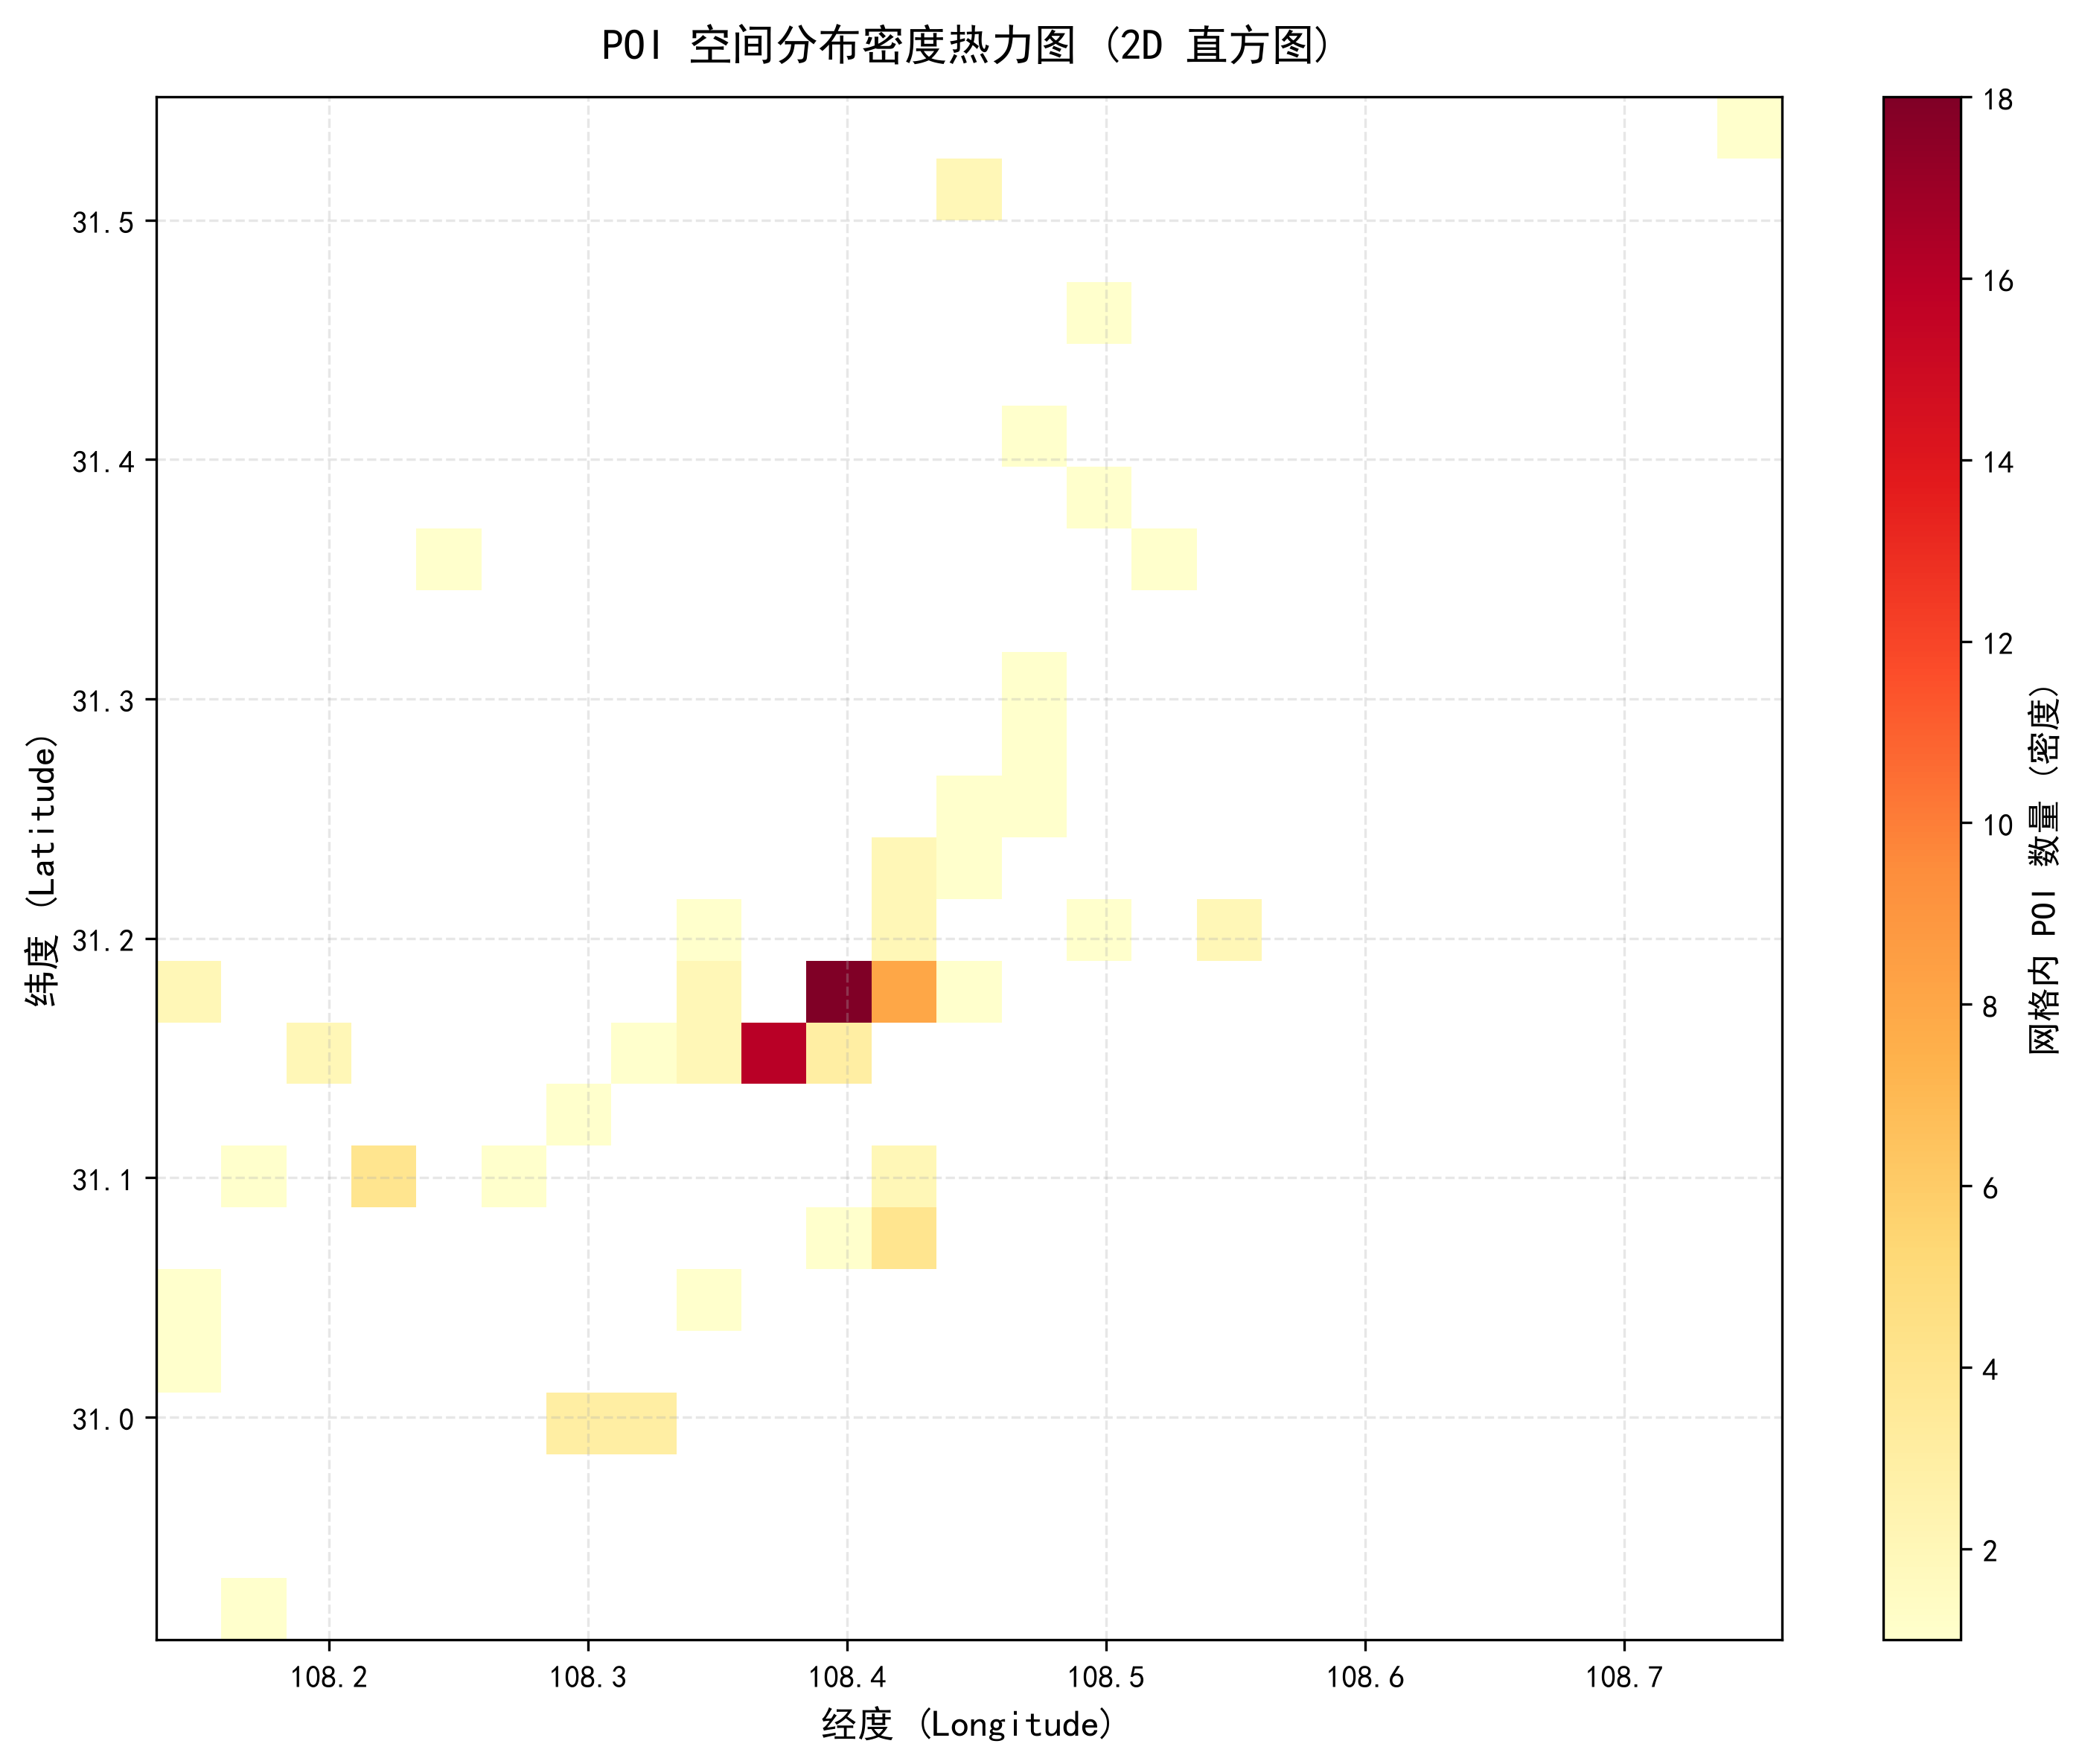

In [8]:
# POI 空间密度 2D 直方图 
import matplotlib.pyplot as plt

print("【高级分析】正在生成 POI 空间密度 2D 直方图...")

# 创建画布
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

# 提取经纬度浮点数
lons = all_pois_df['lon'].astype(float)
lats = all_pois_df['lat'].astype(float)

# 创建 2D 直方图
h = ax.hist2d(lons, lats, bins=25, cmap='YlOrRd', cmin=1)

# 添加右侧颜色条
cbar = plt.colorbar(h[3], ax=ax)
cbar.set_label('网格内 POI 数量 (密度)', fontsize=11)

# 设置坐标轴与标题
ax.set_xlabel('经度 (Longitude)', fontsize=12)
ax.set_ylabel('纬度 (Latitude)', fontsize=12)
ax.set_title('POI 空间分布密度热力图 (2D 直方图)', fontsize=14, fontweight='bold', pad=12)
ax.grid(True, linestyle='--', alpha=0.3)

# 保存并展示
plt.tight_layout()
plt.savefig('./data/poi_density_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()